In [7]:
import pandas as pd
import matplotlib.pyplot as plt

In [8]:
df = pd.read_csv("https://raw.githubusercontent.com/abulbasar/data/refs/heads/master/iris.csv")
df

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


In [9]:
X = df[['SepalLengthCm', 'PetalLengthCm']]

<Axes: xlabel='SepalLengthCm', ylabel='PetalLengthCm'>

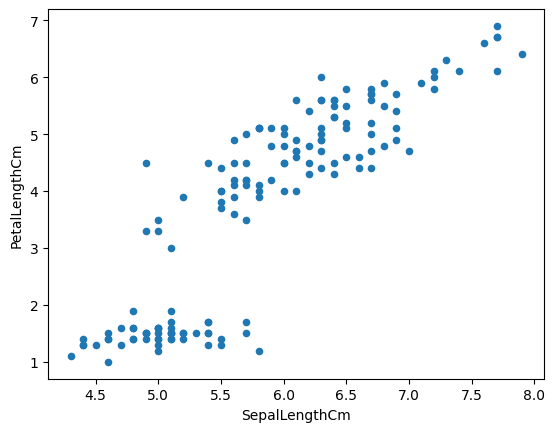

In [10]:
X.plot.scatter(0, 1)

In [11]:
df

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


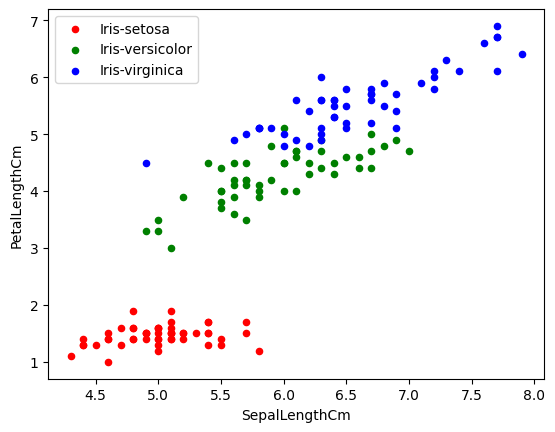

In [13]:
fig, ax = plt.subplots()
colors = ['red', 'green', 'blue']
for i, s in enumerate(df.Species.unique()):
    X[df.Species == s].plot.scatter(0, 1, ax = ax, color = colors[i], label = s)
plt.legend()

In [20]:
from sklearn import cluster, preprocessing, metrics

In [15]:
scaler = preprocessing.StandardScaler()
X_std = scaler.fit_transform(X)

In [17]:
kmeans = cluster.KMeans(n_clusters=3, max_iter=1000)
y_pred = kmeans.fit_predict(X_std) # y_pred: cluster id, 0 based
y_pred

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 2, 0, 2, 2, 2, 2, 1, 2, 2, 1, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2,
       2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 1, 2, 2, 2, 0, 2, 0, 0, 2, 0, 0, 0,
       2, 2, 0, 2, 2, 2, 0, 0, 0, 2, 0, 2, 0, 2, 0, 0, 2, 2, 2, 0, 0, 0,
       2, 2, 2, 0, 2, 2, 2, 0, 0, 0, 2, 0, 0, 0, 2, 2, 2, 2], dtype=int32)

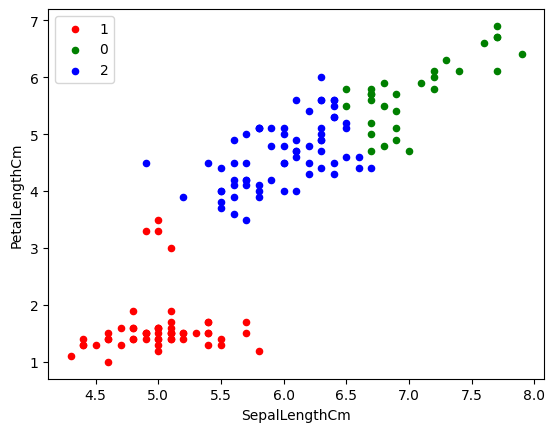

In [19]:
fig, ax = plt.subplots()
colors = ['red', 'green', 'blue']
for i, s in enumerate(pd.Series(y_pred).unique()):
    X[y_pred == s].plot.scatter(0, 1, ax = ax, color = colors[i], label = s)
plt.legend()

In [21]:
metrics.homogeneity_score(df.Species, y_pred)

0.5610380483356423

In [32]:
kmeans.inertia_ # sum((distance between obs and its closed centroid)^2)

141.15417813388652

In [33]:
df.columns

Index(['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm',
       'Species'],
      dtype='str')

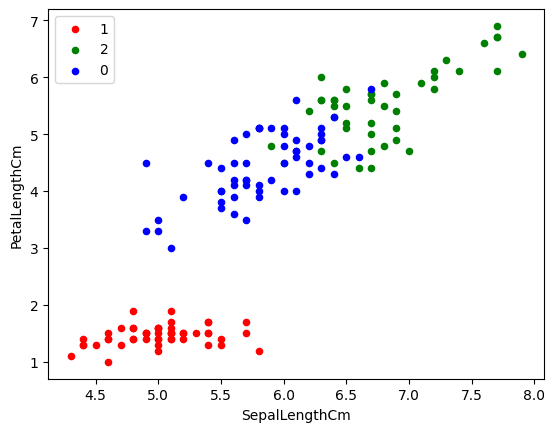

In [34]:
# Form cluster usig all features

scaler = preprocessing.StandardScaler()
X = df[['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']]
X_std = scaler.fit_transform(X)
kmeans = cluster.KMeans(n_clusters=3, max_iter=1000)
y_pred = kmeans.fit_predict(X_std) # y_pred: cluster id, 0 based


fig, ax = plt.subplots()
colors = ['red', 'green', 'blue']
for i, s in enumerate(pd.Series(y_pred).unique()):
    X[y_pred == s].plot.scatter(0, 2, ax = ax, color = colors[i], label = s)
plt.legend()

In [35]:
metrics.homogeneity_score(y_pred, df.Species)

0.6440718321615102

In [37]:
kmeans.cluster_centers_

array([[-0.01139555, -0.87288504,  0.37688422,  0.31165355],
       [-1.01457897,  0.84230679, -1.30487835, -1.25512862],
       [ 1.16743407,  0.15377779,  1.00314548,  1.02963256]])

In [38]:
for i, s in enumerate(pd.Series(y_pred).unique()):
    center = kmeans.cluster_centers_[0]
    a = X_std[y_pred == s] 
    

In [39]:
center

array([-0.01139555, -0.87288504,  0.37688422,  0.31165355])

In [40]:
a

array([[-4.16009689e-01, -1.74477836e+00,  1.37235899e-01,
         1.33225943e-01],
       [ 7.95669016e-01, -5.87763531e-01,  4.78430123e-01,
         3.96171883e-01],
       [-1.73673948e-01, -5.87763531e-01,  4.21564419e-01,
         1.33225943e-01],
       [-1.14301691e+00, -1.51337539e+00, -2.60824029e-01,
        -2.61192967e-01],
       [ 9.16836886e-01, -3.56360566e-01,  4.78430123e-01,
         1.33225943e-01],
       [-7.79513300e-01, -8.19166497e-01,  8.03701950e-02,
         2.64698913e-01],
       [-1.02184904e+00, -2.43898725e+00, -1.47092621e-01,
        -2.61192967e-01],
       [ 6.86617933e-02, -1.24957601e-01,  2.50967307e-01,
         3.96171883e-01],
       [ 1.89829664e-01, -1.97618132e+00,  1.37235899e-01,
        -2.61192967e-01],
       [ 3.10997534e-01, -3.56360566e-01,  5.35295827e-01,
         2.64698913e-01],
       [-2.94841818e-01, -3.56360566e-01, -9.02269170e-02,
         1.33225943e-01],
       [-2.94841818e-01, -1.24957601e-01,  4.21564419e-01,
      

In [41]:
from scipy.spatial import distance

In [42]:
distance.euclidean(a, center)

array([1.00656757, 0.86608453, 0.37611339, 1.55744012, 1.08192466,
       0.82644774, 2.01900898, 0.76733503, 1.28192773, 0.63089921,
       0.77276681, 0.80552896, 0.60509369, 1.19295795, 0.72830313,
       0.52392681, 0.75331023, 0.55350174, 0.87969102, 0.56252004,
       0.81277973, 0.94531917, 1.03459892, 0.43420582, 0.48880321,
       0.91922894, 1.05408799, 0.83963274, 0.64833079, 0.53988073,
       0.8221004 , 0.43212442, 1.58620275, 0.36182724, 0.83523839,
       0.58380073, 0.70721166, 1.34400505, 0.41578173, 0.7253106 ,
       1.25325462, 1.45345363, 1.04668361, 0.92321404, 1.35614787,
       1.17181242, 0.88661635, 0.79072564, 0.74415442, 0.98324741,
       0.74582527, 0.7660847 , 0.93574155, 0.7253106 , 0.98342183,
       0.97164015])

In [44]:
df['distance'] = 0.0
df['cluster'] = y_pred
for i, s in enumerate(pd.Series(y_pred).unique()):
    center = kmeans.cluster_centers_[0]
    a = X_std[y_pred == s] 
    df.loc[y_pred == s, 'distance'] =  distance.euclidean(a, center)
df
    

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,distance,cluster
0,1,5.1,3.5,1.4,0.2,Iris-setosa,3.164035,1
1,2,4.9,3.0,1.4,0.2,Iris-setosa,2.726068,1
2,3,4.7,3.2,1.3,0.2,Iris-setosa,3.023865,1
3,4,4.6,3.1,1.5,0.2,Iris-setosa,2.931518,1
4,5,5.0,3.6,1.4,0.2,Iris-setosa,3.343123,1
...,...,...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica,1.774215,2
146,147,6.3,2.5,5.0,1.9,Iris-virginica,0.983422,0
147,148,6.5,3.0,5.2,2.0,Iris-virginica,1.398985,2
148,149,6.2,3.4,5.4,2.3,Iris-virginica,2.144370,2


In [45]:
df.cluster.value_counts()

cluster
0    56
1    50
2    44
Name: count, dtype: int64

In [46]:
df.groupby('cluster').distance.agg(['sum', 'count'])

,sum,count
cluster,,
0,49.059154,56
1,158.401937,50
2,87.362010,44


In [48]:
df['anomaly'] = False

# Find the anomaly using mean + 3 sigma threshold

for i, s in enumerate(pd.Series(y_pred).unique()):
    distances = df[df.cluster == s].distance
    df.loc[df.cluster == s, 'anomaly'] =  distances > (distances.mean() + 3 * distances.std())
df

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,distance,cluster,anomaly
0,1,5.1,3.5,1.4,0.2,Iris-setosa,3.164035,1,False
1,2,4.9,3.0,1.4,0.2,Iris-setosa,2.726068,1,False
2,3,4.7,3.2,1.3,0.2,Iris-setosa,3.023865,1,False
3,4,4.6,3.1,1.5,0.2,Iris-setosa,2.931518,1,False
4,5,5.0,3.6,1.4,0.2,Iris-setosa,3.343123,1,False
...,...,...,...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica,1.774215,2,False
146,147,6.3,2.5,5.0,1.9,Iris-virginica,0.983422,0,False
147,148,6.5,3.0,5.2,2.0,Iris-virginica,1.398985,2,False
148,149,6.2,3.4,5.4,2.3,Iris-virginica,2.144370,2,False


In [49]:
df[df.anomaly]

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,distance,cluster,anomaly
15,16,5.7,4.4,1.5,0.4,Iris-setosa,4.532230,1,True
60,61,5.0,2.0,3.5,1.0,Iris-versicolor,2.019009,0,True


In [51]:

for i, s in enumerate(pd.Series(y_pred).unique()):
    distances = df[df.cluster == s].distance
    print(s, "threshold: ", distances.mean() + 3 * distances.std())

1 threshold:  4.397346945850284
2 threshold:  3.9141168531946122
0 threshold:  1.860790070254815
